# 04 – Descriptive statistics (Day 9)

**Scope:** 2026 January–September CPI data. State comparisons exclude the `All India` aggregate. State means are unweighted: each state contributes one observation regardless of population or expenditure weight. Published inflation is already a year-on-year rate.

Run from this notebook. Final report figures are saved to `report/figures/`.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
cpi = pd.read_csv(ROOT / "data/cleaned/cpi_clean.csv")
months = ["January", "February", "March", "April", "May", "June", "July", "August", "September"]
df = cpi[(cpi["year"] == 2026) & (cpi["month_num"] <= 9)].copy()
state_rows = df[~df["is_aggregate"]].copy()
print("2026 Jan–Sep rows:", len(df))
print("States/UTs (excluding All India):", state_rows["state"].nunique())

2026 Jan–Sep rows: 12870
States/UTs (excluding All India): 36


## 1. All India, Combined: division summaries

Each row summarizes the nine monthly published inflation rates for one division. `std` is the sample standard deviation across those nine months.

In [2]:
all_india = df[(df["state"] == "All India") & (df["sector"] == "Combined")]
division_summary = (all_india.groupby("division")["inflation"]
                    .agg(n="count", mean="mean", median="median", std="std", min="min", max="max")
                    .sort_values("mean", ascending=False))
display(division_summary.round(3))

,n,mean,median,std,min,max
division,,,,,,
"Personal care, social protection and miscellaneous goods and services",9,17.096,17.66,2.104,13.75,19.65
Restaurants and accommodation services,9,5.646,5.74,2.576,2.73,9.36
Food and beverages,9,4.562,4.55,1.512,2.11,7.36
"Paan, tobacco and intoxicants",9,4.364,4.77,0.714,2.86,4.83
CPI (General),9,3.996,3.93,0.884,2.74,5.54
Education services,9,3.424,3.35,0.300,2.99,3.94
Clothing and footwear,9,3.156,2.98,0.402,2.75,3.93
Transport,9,2.240,1.75,2.309,-0.05,5.01
"Recreation, sport and culture",9,2.039,2.11,0.289,1.64,2.47


## 2. September state inflation: quartiles, IQR and outliers

The IQR fences are a descriptive flag, not proof of an error. Do not remove an observation solely because it falls outside a fence.

In [3]:
sept_general = state_rows[(state_rows["month"] == "September") &
                          (state_rows["sector"] == "Combined") &
                          (state_rows["division"] == "CPI (General)")].copy()
values = sept_general["inflation"].dropna()
q1, median, q3 = values.quantile([0.25, 0.50, 0.75])
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr
outliers = sept_general[(sept_general["inflation"] < lower_fence) | (sept_general["inflation"] > upper_fence)]
print({"n": len(values), "Q1": q1, "median": median, "Q3": q3, "IQR": iqr,
       "lower_fence": lower_fence, "upper_fence": upper_fence})
display(outliers[["state", "inflation"]])

{'n': 36, 'Q1': 4.035, 'median': 5.06, 'Q3': 5.87, 'IQR': 1.835, 'lower_fence': 1.2825000000000002, 'upper_fence': 8.6225}


,state,inflation


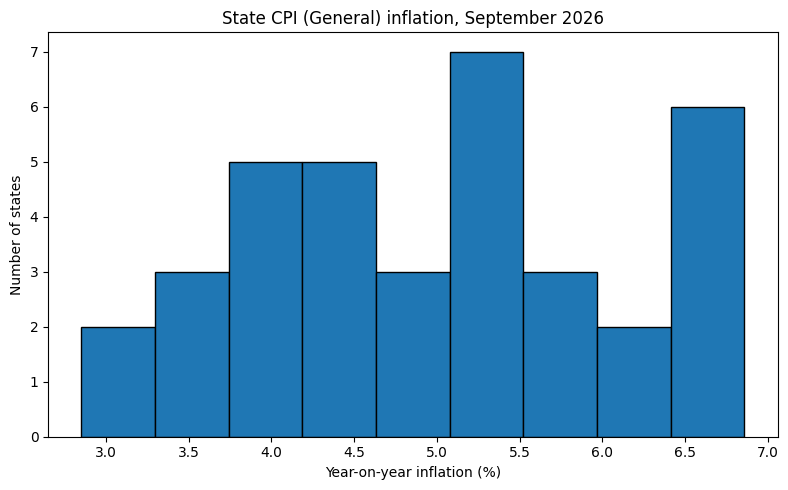

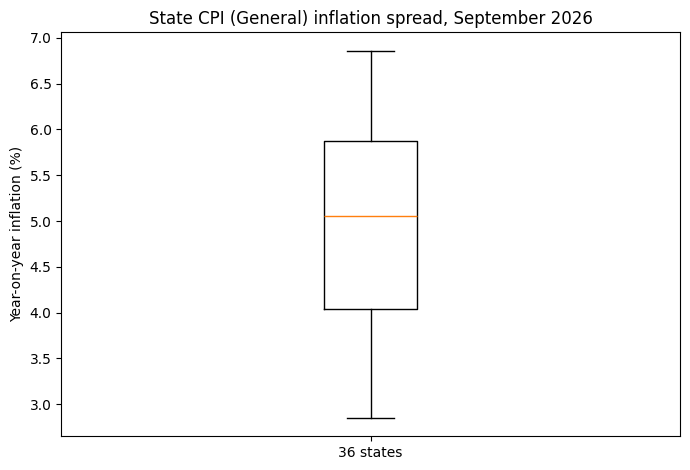

In [4]:
fig_dir = ROOT / "report/figures"
fig_dir.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(values, bins=9, edgecolor="black")
ax.set(title="State CPI (General) inflation, September 2026", xlabel="Year-on-year inflation (%)", ylabel="Number of states")
fig.tight_layout()
fig.savefig(fig_dir / "september_state_inflation_histogram.png", dpi=180)
plt.show()
fig, ax = plt.subplots(figsize=(7, 4.8))
ax.boxplot(values, tick_labels=["36 states"])
ax.set(title="State CPI (General) inflation spread, September 2026", ylabel="Year-on-year inflation (%)")
fig.tight_layout()
fig.savefig(fig_dir / "september_state_inflation_boxplot.png", dpi=180)
plt.show()

## 3. Cross-state spread over time

For each month, calculate the range (maximum minus minimum) and sample standard deviation across states. A smaller range does not necessarily mean the whole distribution is becoming less dispersed, so read both measures.

,month_num,month,n,minimum,maximum,sd,gap
0,1,January,36,0.12,4.92,0.990,4.80
1,2,February,36,0.11,5.02,0.907,4.91
2,3,March,36,0.66,5.84,0.971,5.18
3,4,April,36,0.69,5.81,0.916,5.12
4,5,May,36,1.03,6.14,0.980,5.11
5,6,June,36,1.63,6.36,1.042,4.73
6,7,July,36,1.84,6.32,1.021,4.48
7,8,August,36,2.34,6.27,1.067,3.93
8,9,September,36,2.85,6.86,1.127,4.01


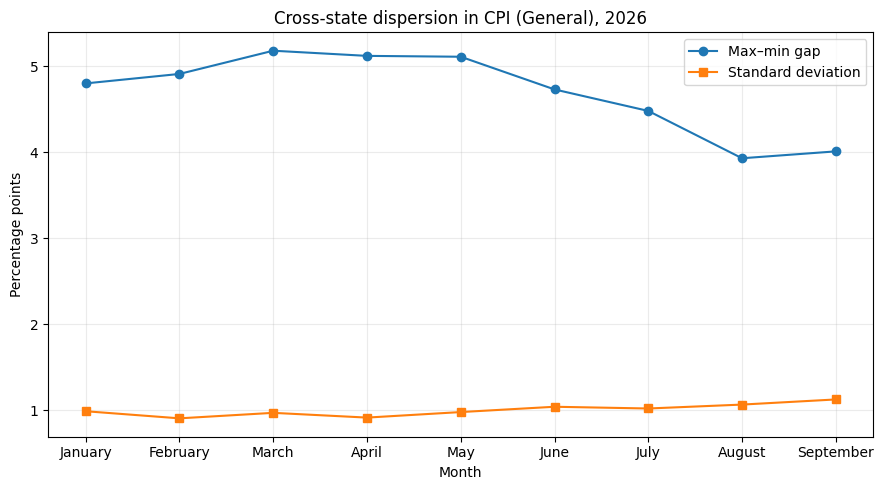

In [5]:
monthly_spread = (state_rows[(state_rows["sector"] == "Combined") & (state_rows["division"] == "CPI (General)")]
                  .groupby(["month_num", "month"])["inflation"]
                  .agg(n="count", minimum="min", maximum="max", sd="std").reset_index()
                  .sort_values("month_num"))
monthly_spread["gap"] = monthly_spread["maximum"] - monthly_spread["minimum"]
display(monthly_spread.round(3))
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(monthly_spread["month"], monthly_spread["gap"], marker="o", label="Max–min gap")
ax.plot(monthly_spread["month"], monthly_spread["sd"], marker="s", label="Standard deviation")
ax.set(title="Cross-state dispersion in CPI (General), 2026", ylabel="Percentage points", xlabel="Month")
ax.legend(); ax.grid(alpha=0.25); fig.tight_layout()
fig.savefig(fig_dir / "monthly_state_dispersion.png", dpi=180)
plt.show()

## 4. September rural–urban gap by state

Gap is defined as **Rural minus Urban** percentage points. Chandigarh is absent because the source has no Rural rows for it.

In [6]:
rural_urban = state_rows[(state_rows["month"] == "September") &
                         (state_rows["division"] == "CPI (General)") &
                         (state_rows["sector"].isin(["Rural", "Urban"]))]
rural_urban = rural_urban.pivot(index="state", columns="sector", values="inflation").dropna()
rural_urban["rural_minus_urban"] = rural_urban["Rural"] - rural_urban["Urban"]
display(rural_urban.sort_values("rural_minus_urban").round(2))
print("Paired states:", len(rural_urban), "; mean gap:", round(rural_urban["rural_minus_urban"].mean(), 3),
      "; median gap:", round(rural_urban["rural_minus_urban"].median(), 3))

sector,Rural,Urban,rural_minus_urban
state,,,
The Dadra And Nagar Haveli And Daman And Diu,5.57,6.93,-1.36
Himachal Pradesh,3.93,4.50,-0.57
Jammu And Kashmir,4.12,4.65,-0.53
Tripura,3.85,4.33,-0.48
Goa,3.67,4.07,-0.40
Nagaland,3.28,3.12,0.16
Puducherry,7.07,6.77,0.30
Meghalaya,3.72,3.22,0.50
Mizoram,3.14,2.63,0.51


Paired states: 35 ; mean gap: 0.91 ; median gap: 1.0


## 5. Extreme values by division

Apply the 1.5 × IQR rule separately to the September 2026 Combined state values in each division. Keep flagged observations in the dataset and investigate them against source material.

In [7]:
division_outlier_rows = []
for division, group in state_rows[(state_rows["month"] == "September") & (state_rows["sector"] == "Combined")].groupby("division"):
    vals = group["inflation"].dropna()
    q1, q3 = vals.quantile([0.25, 0.75]); iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flagged = group[(group["inflation"] < low) | (group["inflation"] > high)]
    division_outlier_rows.append({"division": division, "n": len(vals), "Q1": q1, "median": vals.median(), "Q3": q3,
                                  "IQR": iqr, "lower_fence": low, "upper_fence": high,
                                  "outliers": "; ".join(f"{r.state} ({r.inflation:.2f})" for r in flagged.itertuples())})
division_outliers = pd.DataFrame(division_outlier_rows)
display(division_outliers)
ladakh_tobacco = state_rows[(state_rows["month"] == "September") & (state_rows["state"] == "Ladakh") &
                            (state_rows["sector"] == "Combined") & (state_rows["division"] == "Paan, tobacco and intoxicants")]
display(ladakh_tobacco[["state", "division", "cpi_index", "inflation"]])
print("Flagged values are retained; Ladakh tobacco is not deleted or winsorised.")

,division,n,Q1,median,Q3,IQR,lower_fence,upper_fence,outliers
0,CPI (General),36,4.0350,5.060,5.8700,1.8350,1.28250,8.62250,
1,Clothing and footwear,36,1.7900,3.715,4.4825,2.6925,-2.24875,8.52125,
2,Education services,36,1.9825,3.630,5.3825,3.4000,-3.11750,10.48250,Ladakh (12.50)
3,Food and beverages,36,4.5600,6.400,7.9050,3.3450,-0.45750,12.92250,
4,"Furnishings, household equipment and routine h...",36,1.9600,2.925,3.4925,1.5325,-0.33875,5.79125,
5,Health,36,1.0300,1.420,2.0050,0.9750,-0.43250,3.46750,
6,"Housing, water, electricity, gas and other fuels",36,2.3200,2.700,3.4150,1.0950,0.67750,5.05750,Madhya Pradesh (5.84); Odisha (5.12); The Dadr...
7,Information and communication,36,1.5950,2.160,2.6750,1.0800,-0.02500,4.29500,Rajasthan (5.30)
8,"Paan, tobacco and intoxicants",36,3.6300,4.870,6.5850,2.9550,-0.80250,11.01750,Goa (-2.08); Jammu And Kashmir (11.15); Ladakh...
9,"Personal care, social protection and miscellan...",36,6.2500,11.530,15.1650,8.9150,-7.12250,28.53750,


,state,division,cpi_index,inflation
22739,Ladakh,"Paan, tobacco and intoxicants",145.04,38.07


Flagged values are retained; Ladakh tobacco is not deleted or winsorised.


## 6. Export report tables

These CSVs preserve the numerical results used in the written findings.

In [8]:
(ROOT / "report").mkdir(exist_ok=True)
division_summary.to_csv(ROOT / "report/division_summary.csv")
sept_general[["state", "inflation"]].to_csv(ROOT / "report/september_state_inflation.csv", index=False)
monthly_spread.to_csv(ROOT / "report/monthly_state_spread.csv", index=False)
rural_urban.to_csv(ROOT / "report/september_rural_urban_gap.csv")
division_outliers.to_csv(ROOT / "report/september_division_iqr_outliers.csv", index=False)
print("Saved descriptive tables and report figures.")

Saved descriptive tables and report figures.
